In [1]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np
import os, sys
import pandas as pd
from cmcrameri import cm
import matplotlib as mpl
from matplotlib.colors import LogNorm
import pickle
import re
os.environ["TF_USE_LEGACY_KERAS"] = "1"
import tensorflow as tf
from joblib import Parallel, delayed
from matplotlib.ticker import LogLocator, LogFormatter, FuncFormatter, NullFormatter, FormatStrFormatter
import numpy as np
import pickle
import pennylane as qml
sys.path.append('../')
from libs import dataloading, qnn_models, circuits
from libs.helpers import mix_with_white
plt.style.use('../libs/notebookstyle_aps.mplstyle')

%load_ext autoreload
%autoreload 2

I0000 00:00:1792179607.782375 3417067 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792179609.941891 3417067 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792179616.565875 3417067 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


## Plot an overview of the R² values of all models

### quantum models

In [2]:
dfq = pd.read_csv('../results/QNN_results/QNN_r2.txt', header = 0, index_col = 0)

In [3]:
def parse_config(s):
    match = re.match(r"(\d+)qubits_circuit_([a-zA-Z]+)_([a-zA-Z]+)_freq(\d+)enc_(\d+)dec_([a-zA-Z]+)", s)
    if match:
        qubits, enc_angles, angles, n_enc, n_dec,  entanglement = match.groups()
        return int(qubits), int(n_enc), int(n_dec), entanglement, angles, enc_angles
    return None, None, None, None

dfq[['n_qubits', 'n_enc', 'n_dec', 'entanglement','angles','enc_angles']] = dfq['model_name'].apply(lambda x: pd.Series(parse_config(x)))
dfq['nonlocal'] = (dfq.entanglement == 'nonlocal')*1.
dfq['n_params'] = dfq.n_qubits*(dfq.n_enc + dfq.n_dec)*dfq.angles.apply(lambda s: len(s)) + dfq.n_qubits*dfq.n_enc*dfq.enc_angles.apply(lambda s: len(s))

In [4]:
dfqm = dfq.drop(columns = ['key','n_qubits', 'n_enc', 'n_dec', 'entanglement','angles','enc_angles', 'nonlocal']).groupby('model_name').aggregate(['mean','std']).reset_index()
dfqm[['n_qubits', 'n_enc', 'n_dec', 'entanglement','angles','enc_angles']] = dfqm['model_name'].apply(lambda x: pd.Series(parse_config(x)))
dfqm['nonlocal'] = (dfqm.entanglement == 'nonlocal')*1.
dfqm['n_params'] = dfqm.n_qubits*(dfqm.n_enc + dfqm.n_dec)*dfqm.angles.apply(lambda s: len(s)) + dfqm.n_qubits*dfqm.n_enc*dfqm.enc_angles.apply(lambda s: len(s))

### classical models

In [5]:
df = pd.read_csv('../results/cl_results/clNN_r2.txt', header = None, index_col = None)
df.columns = ['runnr','model_name','r2_train_unscaled', 'r2_val_unscaled', 'r2_train', 'r2_val', 'mse_train', 'mse_val' ]

In [6]:
model_list_all = !ls '../results/cl_models/'
model_list = [s for s in model_list_all if ((s[-2:] == '_1') and ('_' in s[:-2]))]
models = []
n_params = []
for model1 in model_list:
    model = tf.keras.models.load_model('../results/cl_models/' + model1)
    models += [model]
    n_params += [[model.name, model.count_params()]]

E0000 00:00:1792179625.879204 3417067 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


In [7]:
df = df.merge(pd.DataFrame(n_params, columns = ['model_name', 'n_params']))
dfm = df.drop(columns = 'model_name').groupby('n_params').aggregate(['mean','std'])

### QNN height dependent plots

In [8]:
jnp_train_inputs, jnp_val_inputs, jnp_train_outputs, jnp_val_outputs = dataloading.load_data(0, n_samples = 'all')
dfq1 = dfq.rename(columns = {'nonlocal':'nonlocal_flag'}) ### otherwise problems occur due to reserved names

In [9]:
def load_eval(mykey, n_qubits, n_enc, n_dec, local_observable, enc_angles, save_dir = "../results/QNN_results", MISSING_LOG = "missing_files.txt"):

    mycircuit = circuits.PQCircuit(
        n_enc, n_dec, n_qubits,
        var_angles="XYZ",
        encoding_angles=enc_angles,
        choose_freq=True,
    )

    dev = qml.device("default.qubit", wires=n_qubits)
    model_qnn, no_params, model_name = qnn_models.make_model(
        dev, mycircuit, local_observable
    )

    fname = f"{save_dir}/{model_name}_optparams{mykey}.npz"

    # if file is missing
    if not os.path.exists(fname):
        with open(MISSING_LOG, "a") as f:
            f.write(fname + "\n")
        return np.nan, np.nan

    opt_pars = np.load(fname)["opt_params"]
    jnp_val_hat = model_qnn(opt_pars, jnp_val_inputs)

    return model_name, jnp_val_hat


In [10]:
row = dfq1.iloc[0]
load_eval(row.key, row.n_qubits, row.n_enc, row.n_dec,
          row.nonlocal_flag, row.enc_angles)

('2qubits_circuit_XYZ_XYZ_freq1enc_0dec_nonlocal',
 Array([ 0.24057278,  0.25974417, -0.480843  , ..., -0.355529  ,
        -0.23768379,  0.38597587], dtype=float32))

In [11]:
calculate_data = False # set true to calculate the data for the vertical profiles
def _process(row):
    model_name, jnp_val_hat = load_eval(
        row.key,
        row.n_qubits,
        row.n_enc,
        row.n_dec,
        row.nonlocal_flag,
        row.enc_angles,
    )
    return (row.key, model_name), jnp_val_hat

if calculate_data:
    res_dict = dict(
        Parallel(
            n_jobs=20,
            backend="loky",
            prefer="processes",
            batch_size=10, 
        )(
            delayed(_process)(row)
            for row in dfq1.itertuples(index=False)
        )
    )
    
    with open("../results/QNN_results/vert_profiles.pkl", "wb") as f:
        pickle.dump(res_dict, f)

/home/b/b309252/.conda/envs/qml_geo_env/lib/python3.11/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


In [12]:
with open("../results/QNN_results/vert_profiles.pkl", "rb") as f:
    res_dict = pickle.load(f)

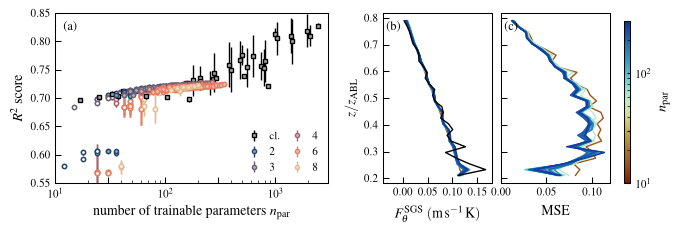

In [16]:
fig = plt.figure(figsize=(6.77, 2.5))

outer = gridspec.GridSpec(
    1, 2,
    width_ratios=[1.2, 1],
    wspace=0.22
)

ax1 = fig.add_subplot(outer[0])

inner = gridspec.GridSpecFromSubplotSpec(
    1, 2,
    subplot_spec=outer[1],
    wspace=0.08
)

ax2 = fig.add_subplot(inner[0])
ax3 = fig.add_subplot(inner[1], sharey=ax2)
ax3.tick_params(labelleft=False)

for ax, lab in zip([ax1, ax2, ax3], ["(a)", "(b)", "(c)"]):
    ax.text(0.03, 0.95, lab, transform=ax.transAxes,
            va="top", ha="left", fontsize=9)

ax1.errorbar(
    dfm.index,
    dfm.r2_val['mean'],
    dfm.r2_val['std'],
    fmt='s',
    markersize=3,
    color='k',
    alpha = 1,
    markerfacecolor='darkgrey',
    label='cl.',
    capsize = 0,
)

colours = cm.lipari(np.linspace(0.15,0.85,5))

for i, (grp_key, grp) in enumerate(dfqm[dfqm.n_enc + dfqm.n_dec > 0].groupby('n_qubits')):
    first = True
    for _, grp2 in grp[(grp.n_enc + grp.n_dec > 3)].groupby(['enc_angles', 'nonlocal']):
        ax1.errorbar(
            grp2.n_params['mean'],
            grp2.r2_val['mean'],
            grp2.r2_val['std'],
            fmt='o',
            markersize=3,
            alpha = 1,
            color=colours[i % len(colours)],
            markerfacecolor=mix_with_white(colours[i % len(colours)], 0.5),
            capsize=0,
            label=str(grp_key) if first else None,
        )
        first = False
        for _, grp2 in grp[(grp.n_enc + grp.n_dec < 4)].groupby(['enc_angles', 'nonlocal']):
            ax1.errorbar(
                grp2.n_params['mean'],
                grp2.r2_val['mean'],
                grp2.r2_val['std'],
                fmt='o',
                markersize=3,
                alpha = 1,
                color=colours[i % len(colours)],
                markerfacecolor='w',
                capsize=0,
                label=str(grp_key) if first else None,
                zorder = -10
            )
        



ax1.set_xscale('log')
current_ticks = ax1.get_xticks()
ax1.set_xticks(list(current_ticks) + [30, 300])
ax1.set_xlim(10, 3e3) 
ax1.set_ylim(0.55, 0.85)
ax1.set_xlabel(r"number of trainable parameters $n_{\rm par}$")
ax1.set_ylabel(r"$R^2$ score")

ax1.legend(
    frameon=False,
    loc="lower right",
    handletextpad=0.4,
    columnspacing=.5,
    ncol = 2
)


dfq3 = dfq[(dfq.r2_val > 0.65)] # select the models on the band with good performance to show height dependence
#bin_edges = np.linspace(0.2, 0.8, 20)
bin_edges = np.linspace(0.2,0.8, 29, endpoint = True)
zs = np.asarray(jnp_val_inputs[:, 2]) / np.pi + 0.5

norm = mpl.colors.Normalize(
    vmin=dfq3["n_params"].min(),
    vmax=dfq3["n_params"].max(),
)


def bin_by_height(zs, y, bin_edges):
    bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])
    out = np.full(len(bin_centers), np.nan)
    for i in range(len(bin_centers)):
        m = (zs >= bin_edges[i]) & (zs < bin_edges[i + 1])
        if m.sum() > 1:
            out[i] = np.mean(y[m])
    return bin_centers, out



norm = LogNorm(vmin=10, vmax=300)
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cm.roma)
sm.set_array([])
y_true = np.asarray(jnp_val_outputs)

for j in dfq3.sort_values('n_params').iloc[::200].index:
        key, model = tuple(dfq3[['key', 'model_name']].loc[j])
        color = cm.roma(norm(dfq3.loc[j, 'n_params']))
        y_pred = np.asarray(res_dict[(key, model)])

        zc, yp = bin_by_height(zs, dataloading.unpreprocess_target(y_pred), bin_edges)
        ax2.plot(-yp, zc, color=color, lw=1)
    
        zc, mse = bin_by_height(zs, (y_true - y_pred) ** 2, bin_edges)
        ax3.plot(mse, zc, color=color, lw=1)
        
zc, yt = bin_by_height(zs, dataloading.unpreprocess_target(y_true), bin_edges)
ax2.plot(-yt, zc, color='k', lw=1)


cax = fig.add_axes([0.92, 0.22, 0.01, 0.65])
cbar = fig.colorbar(sm, cax=cax)
cbar.set_label(r"$n_{\rm par}$")
cbar.ax.yaxis.set_major_locator(LogLocator(base=10, subs=(1, 3)))
cbar.ax.yaxis.set_minor_locator(LogLocator(base=10, subs=(2, 4, 5, 6, 7, 8, 9)))
cbar.ax.yaxis.set_minor_formatter(NullFormatter())
cbar.ax.tick_params(
    which="major",
    direction="in",
    length=2,
    width=0.8,
)


ax2.set_xlabel(r"$F_{\theta}^{\mathrm{SGS}}\;(\mathrm{m\,s^{-1}\,K})$")
ax2.set_ylabel(r"$z/z_{\mathrm{ABL}}$")
ax2.set_xlim(-0.04, 0.18)
ax2.set_xticks([0,0.05, 0.1, 0.15])

ax3.set_xlabel("MSE")
ax3.set_xlim(0.0, 0.12)

plt.subplots_adjust(
    left=0.08,
    right=0.90,
    bottom=0.22,
    top=0.90
)


fig.align_xlabels()
fig.savefig("../figures/R2scores_three_panel.pdf")

In [17]:
df.r2_val.max(), df.n_params.max(), df.r2_val.min()

(0.8376330733299255, 2421, 0.6883213520050049)

In [18]:
dfq.r2_val.max(), dfq.n_params.max(), dfq.r2_val.min()

(0.7293819189071655, 342, 0.0145366787910461)